In [1]:
from laplacians import *

import dionysus as dio
import torch
import numpy as np
import time
import gudhi as gd
import matplotlib.pyplot as plt
import petls

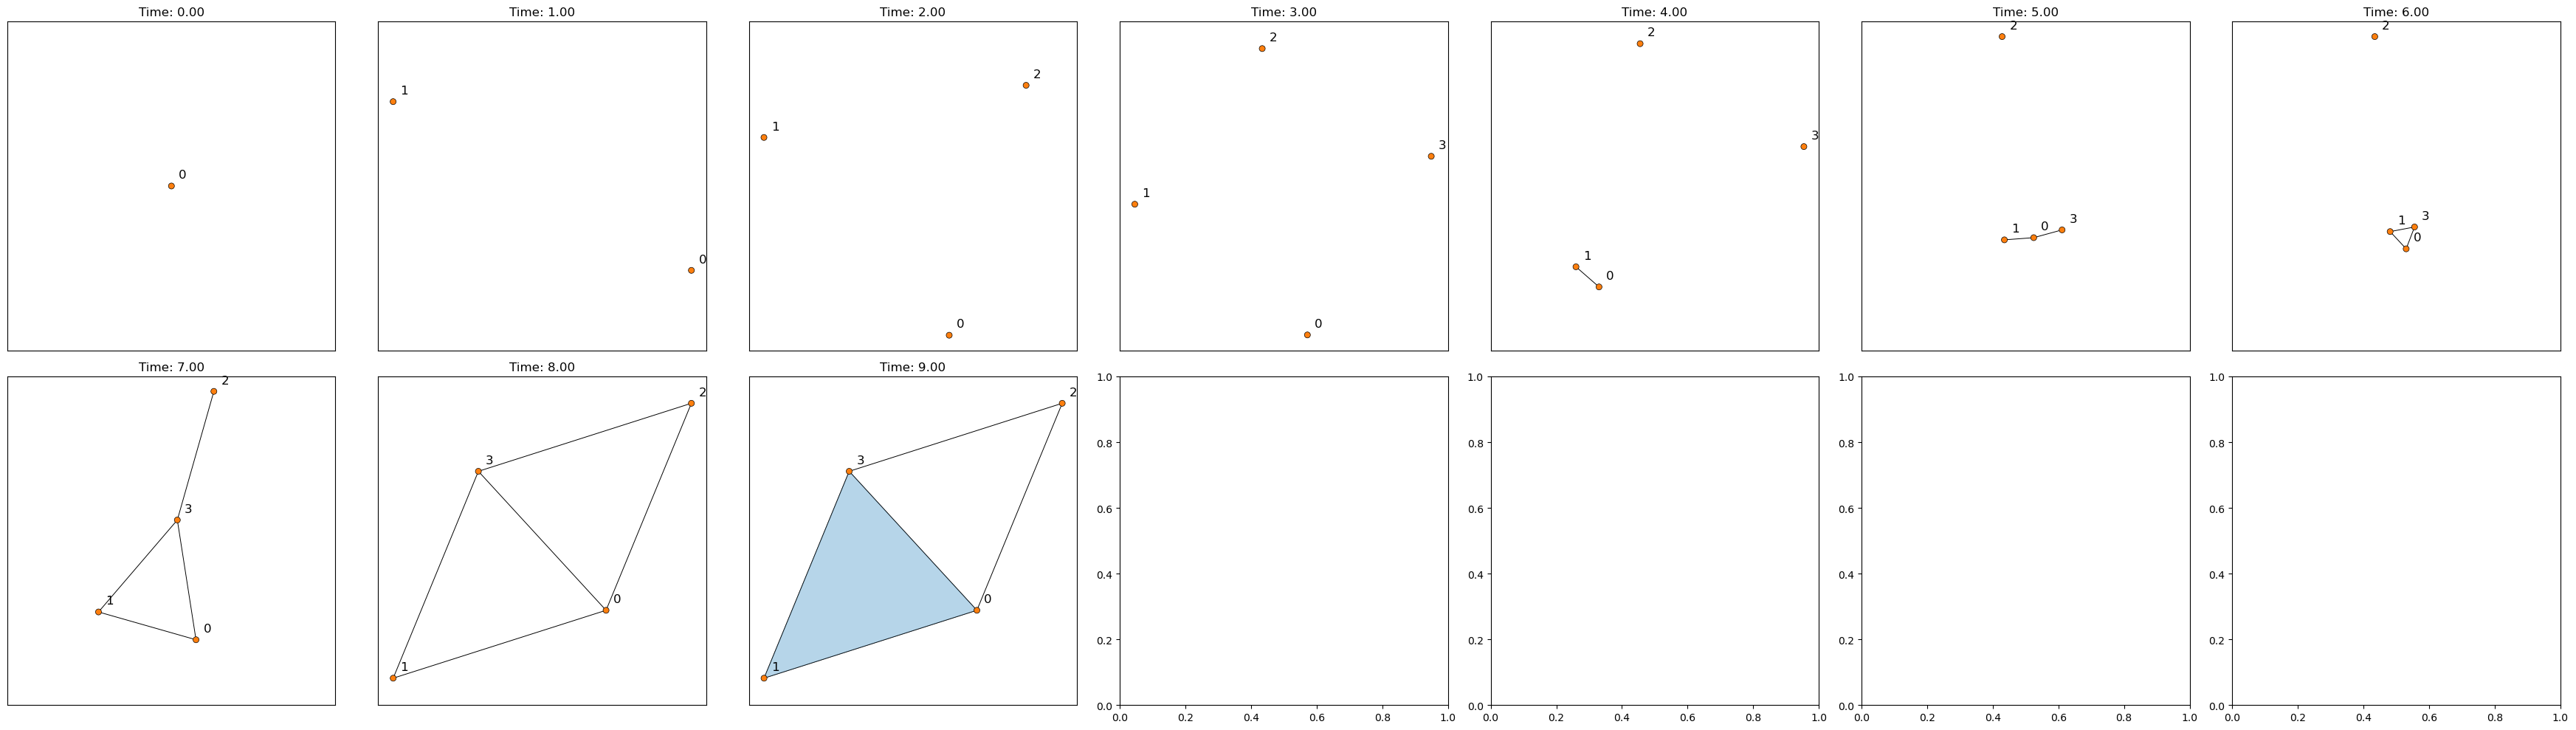

In [2]:
def gudhi_to_dio(st, decimals=10):
    f = dio.Filtration()
    for vertices, time in st.get_filtration():
        f.append(dio.Simplex(vertices, round(time, decimals)))
    return f

def sample_unit_sphere(n, dim=3, rng=None):
    rng = np.random.default_rng(rng)
    points = rng.standard_normal((n, dim))
    return points / np.linalg.norm(points, axis=1, keepdims=True)

simplices = [([0], 0), ([1], 1), ([2], 2), ([3], 3), ([1,0], 4), ([0,3], 5), ([1,3], 6), ([2,3], 7), ([0,2], 8), ([0,1,3], 9)]#, ([0,2,3], 10)]
# simplices = [([0], 0), ([1], 1), ([2], 2), ([3], 3), ([4], 4), ([0,2], 5), 
#              ([2,4], 6), ([1,4], 7), ([0,1], 8), ([3,4], 9), ([2,3], 10), ([1,2], 11), 
#              ([1,3], 12), ([0,3], 13), ([0,2,3], 14), ([1,3,4], 15), ([0,1,3], 16), ([0,1,2], 17),
#              ([2,3,4], 18), ([1,2,4], 19), ([1,2,3], 20), ([0,1,2,3], 21)]

f = dio.Filtration()
for vertices, t in simplices:
    f.append(dio.Simplex(vertices, t))

n_points = 30
# points_in_circle = np.array([[np.cos(2*np.pi*i/n_points), np.sin(2*np.pi*i/n_points)] for i in range(n_points)])
# f_circle = dio.fill_rips(points_in_circle, 5, np.inf)

random_points_on_unit_sphere = sample_unit_sphere(n_points, dim=3, rng=0)

# st = gd.RipsComplex(points=random_points_on_unit_sphere, max_edge_length=np.inf).create_simplex_tree(max_dimension=3)
# f_sphere = gudhi_to_dio(st)
f_sphere = dio.fill_rips(random_points_on_unit_sphere, 3, 1.25)
f_sphere

draw_filtration(f, n_per_row=7)

In [3]:



np.random.seed(0)
random_points = np.random.rand(50, 2)
# st = gd.AlphaComplex(points=random_points).create_simplex_tree()
# st = gd.RipsComplex(points=random_points, max_edge_length=0.1).create_simplex_tree(max_dimension=2)
# f = gudhi_to_dio(st)
f_random = dio.fill_rips(random_points, 5, 0.11)
f_random

Filtration with 112 simplices

In [4]:
chosen_points = random_points
chosen_f = f
threshold = 0.11

## Standard PL

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/10 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


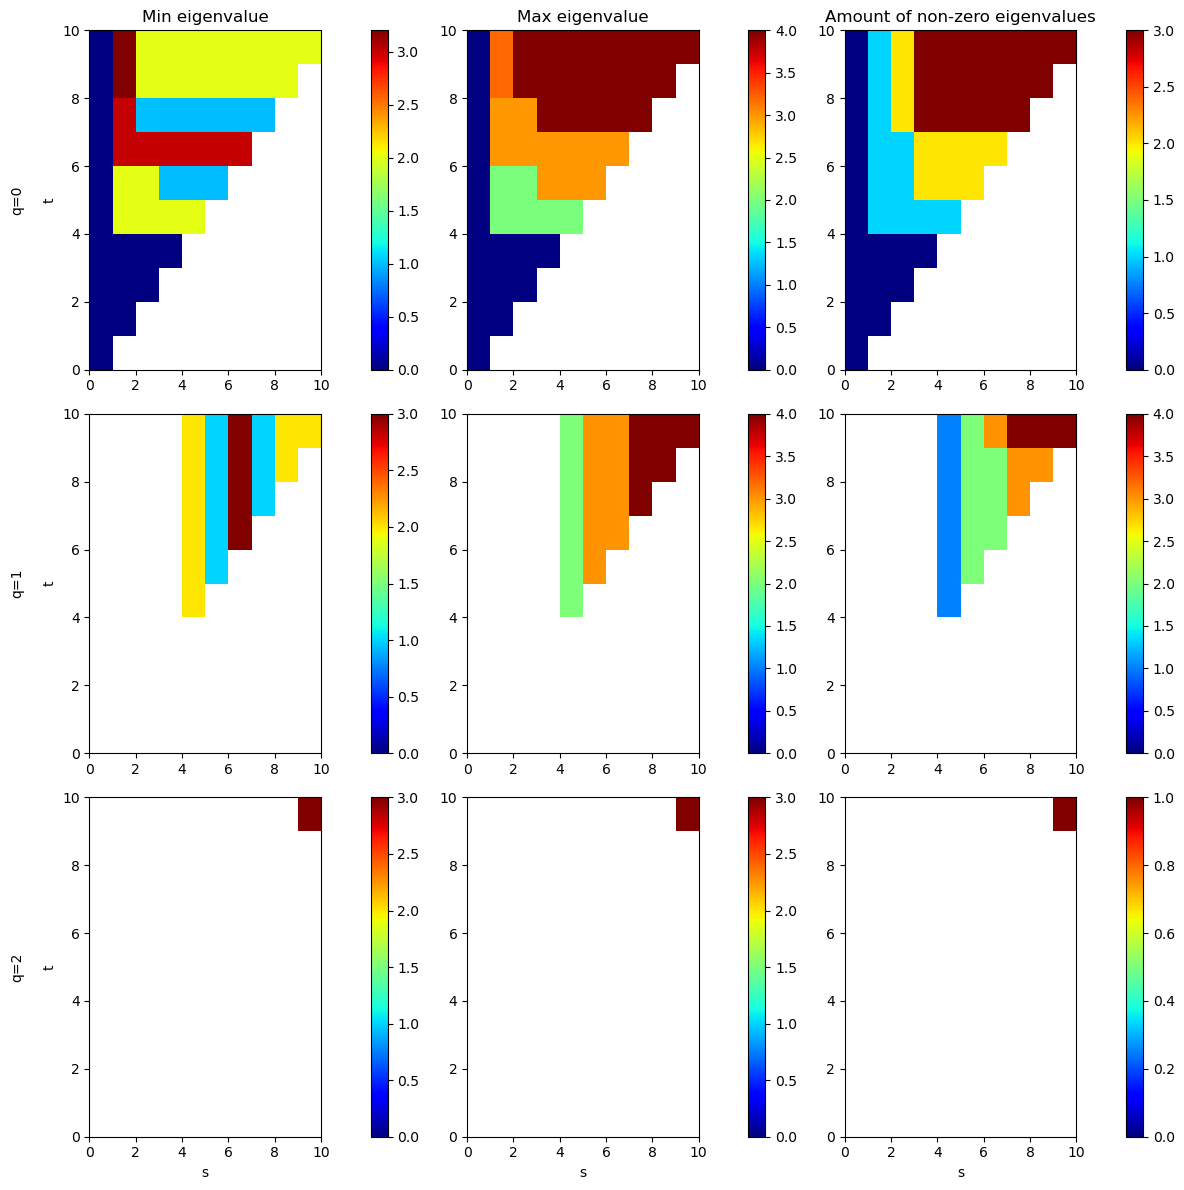

In [5]:
eigenvalues, relevant_times = persistent_Laplacian_eigenvalues(f=chosen_f, up_only=False, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/10 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


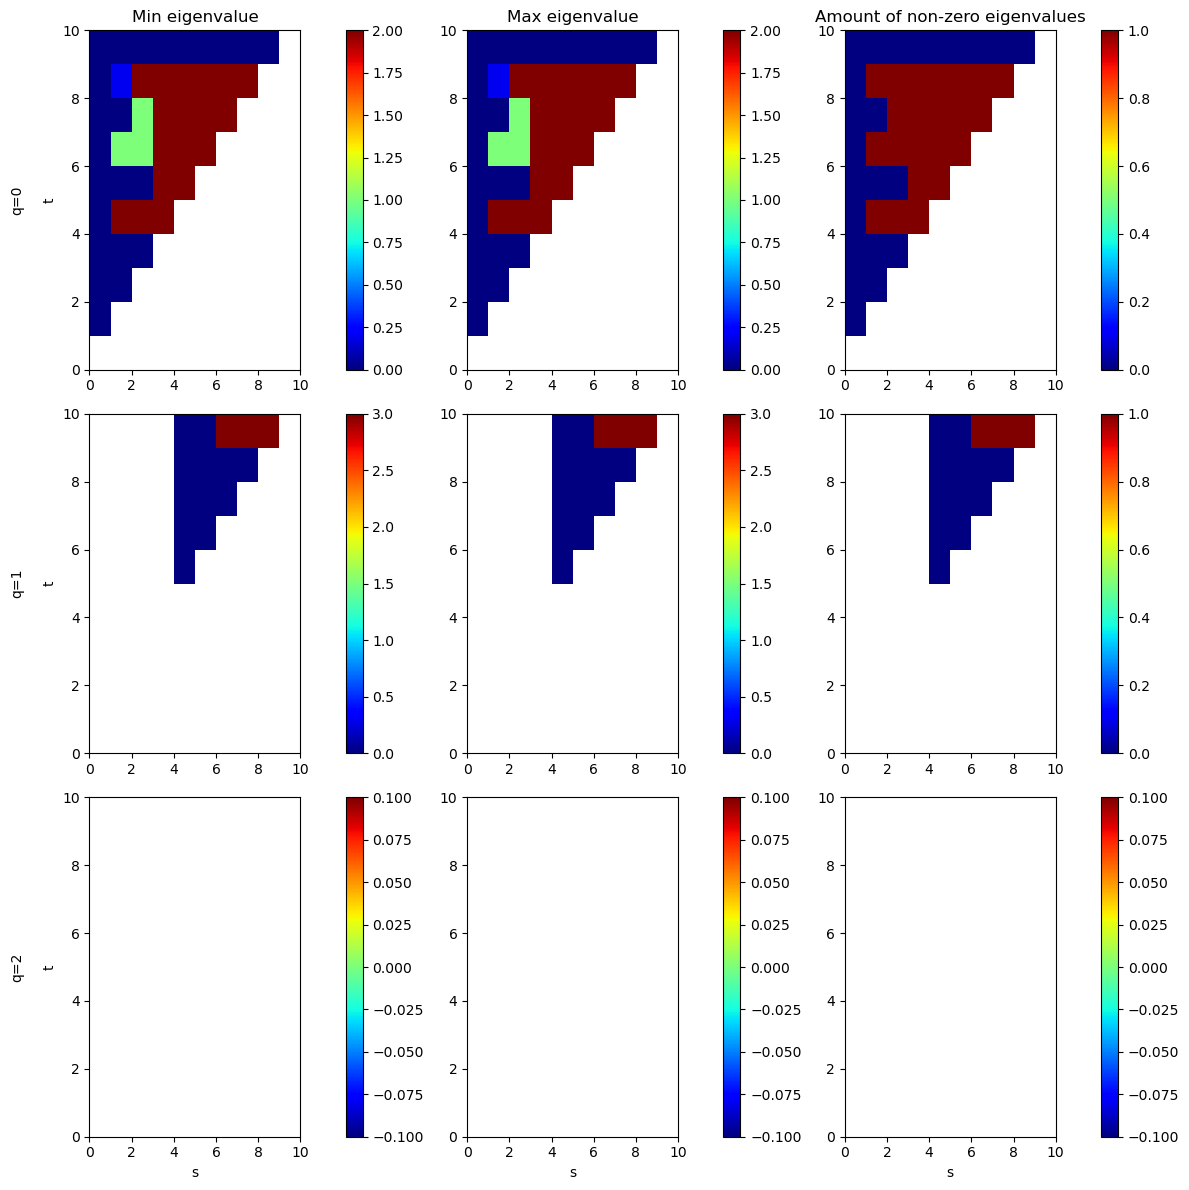

In [6]:
eigenvalues, relevant_times = horizontal_eigenvalues(f=chosen_f, up_only=True, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

Computing boundary matrices:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=0:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=1:   0%|          | 0/10 [00:00<?, ?it/s]

Computing eigenvalues for q=2:   0%|          | 0/10 [00:00<?, ?it/s]

/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


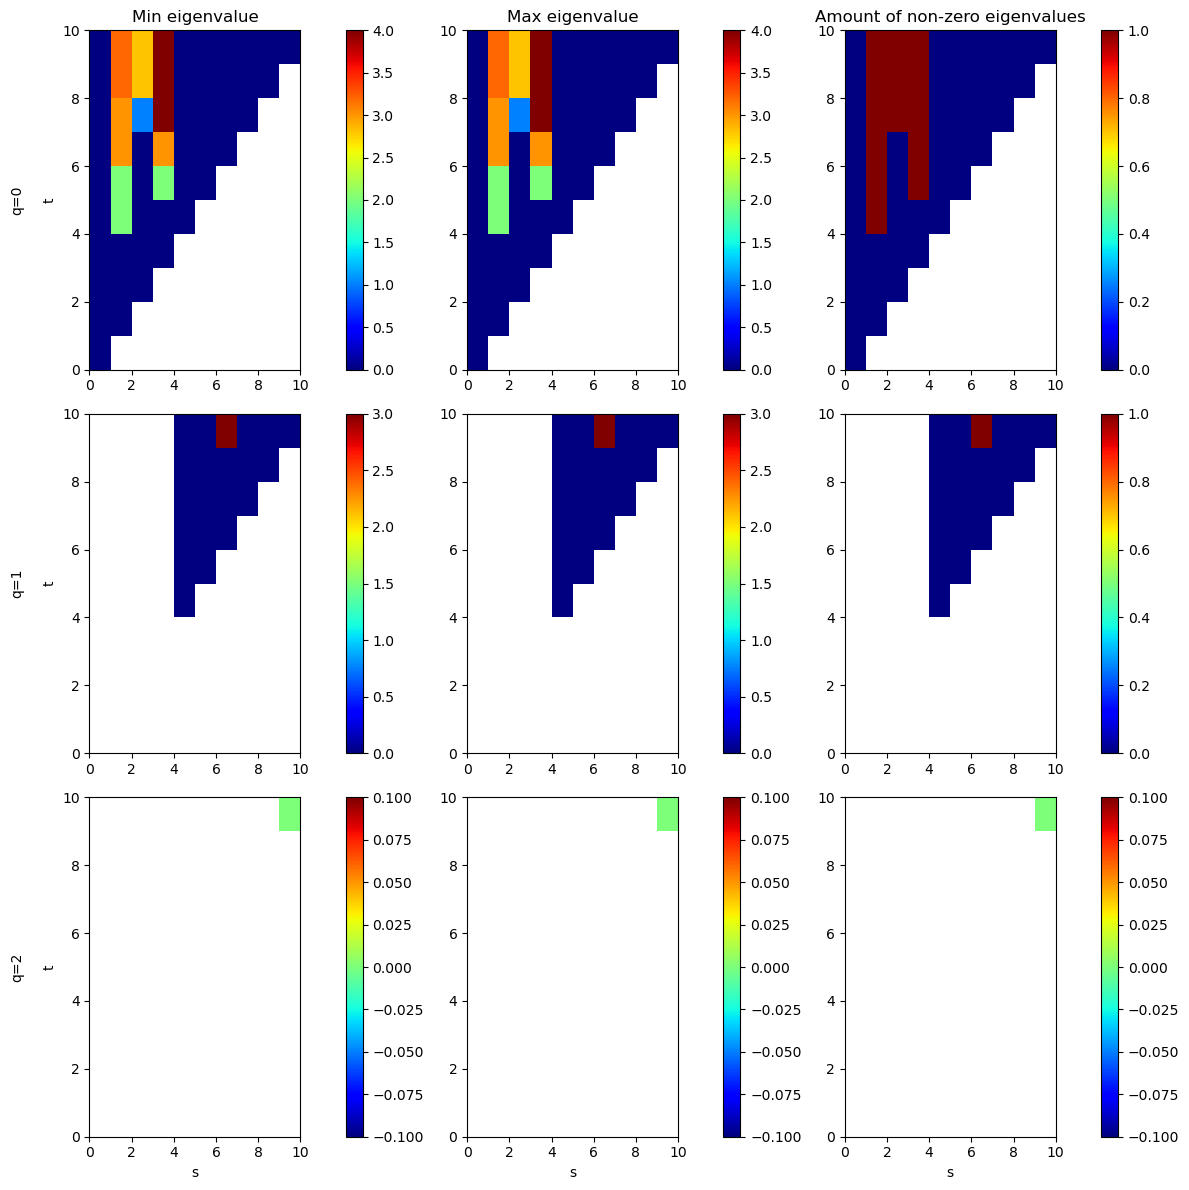

In [7]:
eigenvalues, relevant_times = vertical_eigenvalues(f=chosen_f, up_only=True, max_dim=2)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0})

## With new method

100%|██████████| 1/1 [00:00<00:00, 7108.99it/s]          


Time taken for complete multiplicity operator eigenvalues: 0.07323980331420898


/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


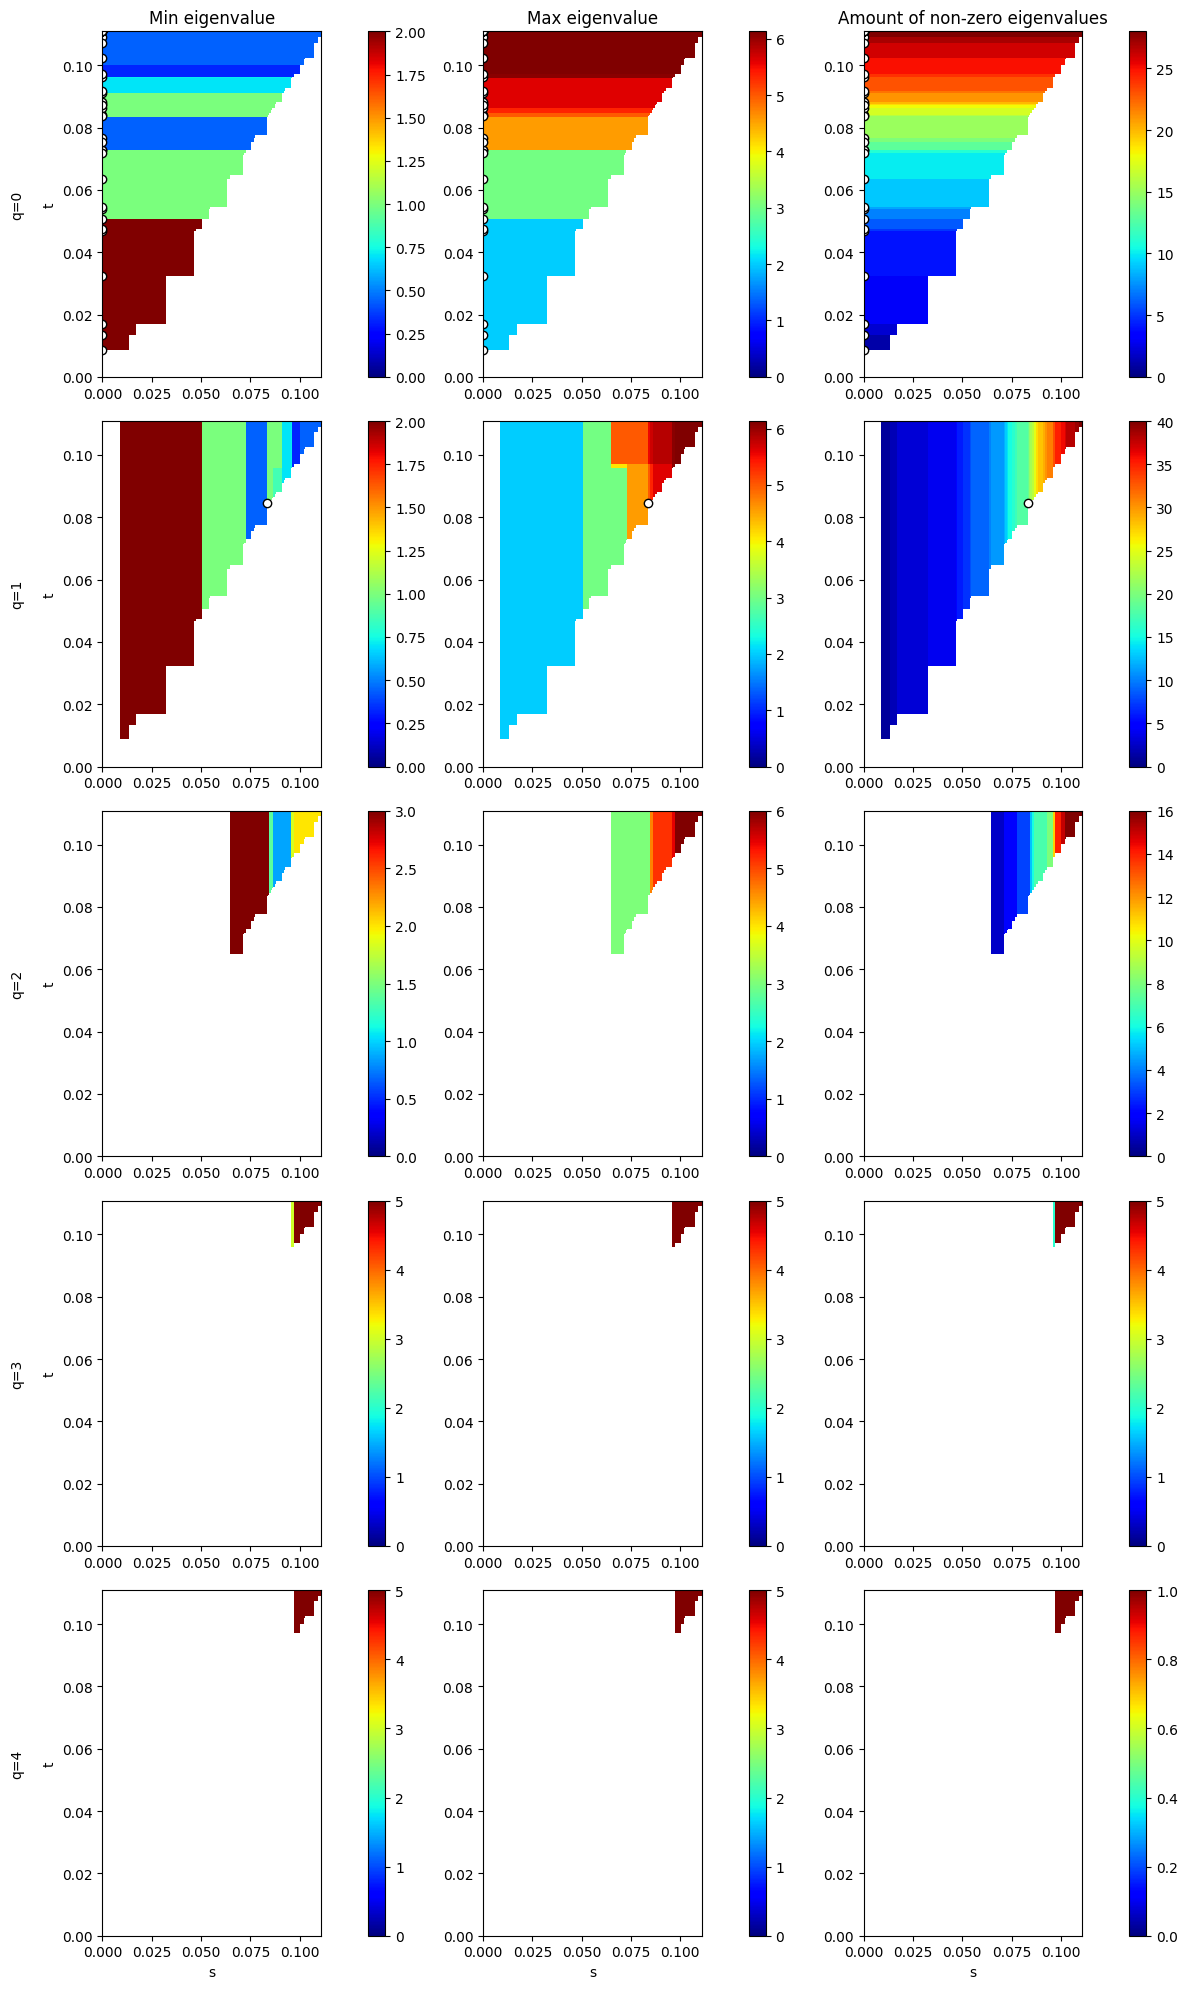

In [6]:
stime = time.time()
# f = dio.fill_rips(random_points, 2, 0.1)
eigenvalues, relevant_times = complete_multiplicity_operator_eigenvalues(f=chosen_f, max_dim=4, up_only=False, fill_eigenvalues=True)
print("Time taken for complete multiplicity operator eigenvalues:", time.time() - stime)
_ = plot_eigenvalues(eigenvalues,  f=chosen_f, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], fill_up_figure=True, plot_args_mesh = {"vmin": 0})

## Other libraries

In [27]:
rips = petls.Rips(points = chosen_points, threshold=threshold)
stime = time.time()
rips.spectra(dim=2, a=1.8, b=2)
print("Time taken for complete multiplicity operator eigenvalues using petls:", time.time() - stime)

Time taken for complete multiplicity operator eigenvalues using petls: 0.00042319297790527344


Time taken for complete multiplicity operator eigenvalues using petls: 0.23182296752929688


/home/siroj/code/NewChainComplexes/laplacians/plot_operator.py:248: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


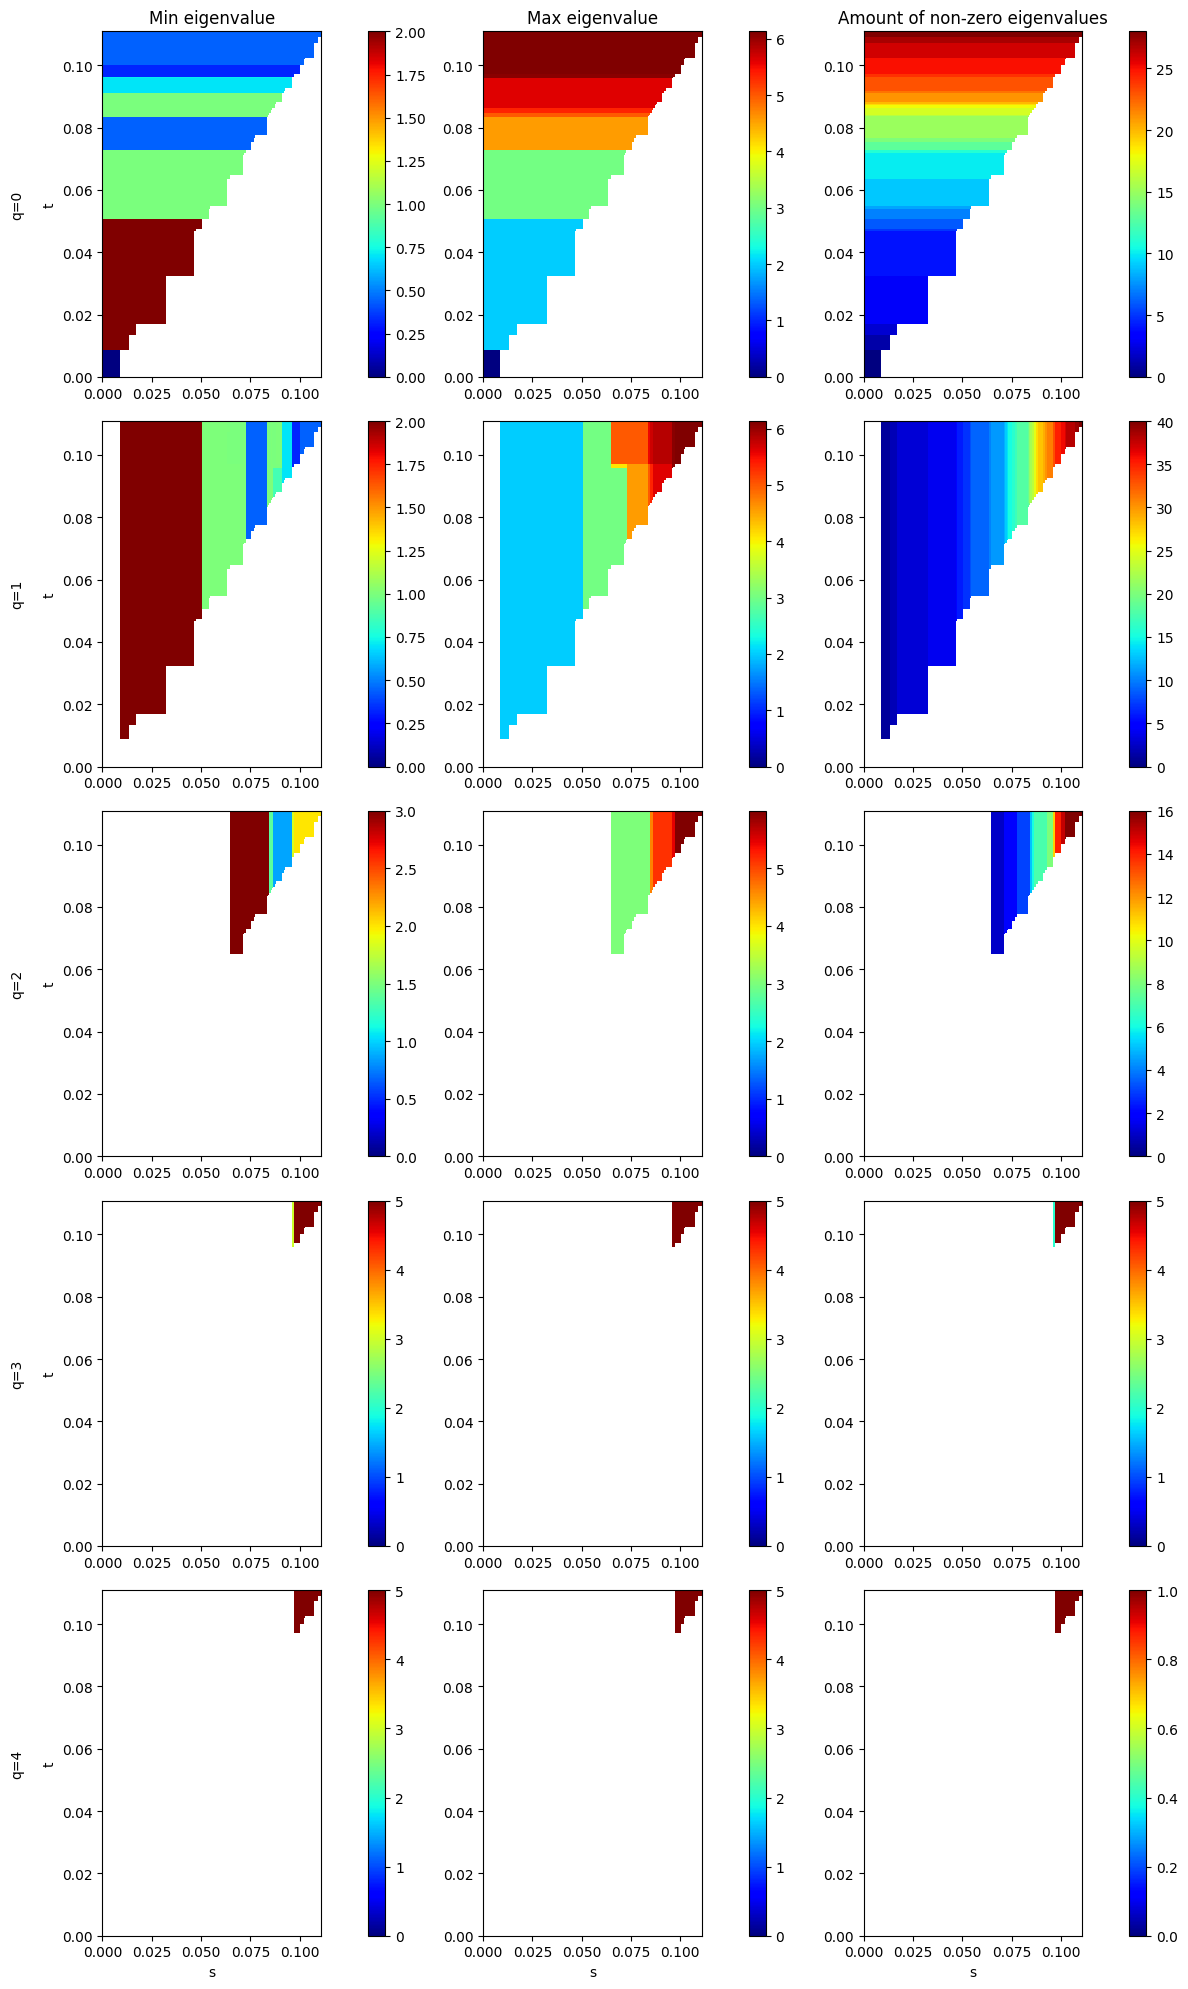

In [7]:

stime = time.time()
spectra = petls.Rips(points = chosen_points, threshold=threshold).spectra(allpairs=True)
# spectra = petls.Rips(points = chosen_points, threshold=np.inf).eigenpairs(allpairs=True)
print("Time taken for complete multiplicity operator eigenvalues using petls:", time.time() - stime)
eigenvalues, relevant_times = petls_output_to_eigenvalues(spectra)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"], plot_args_mesh = {"vmin": 0}, tolerance=1e-5)
# plt.close()
# eigenvalues

Time taken for complete multiplicity operator eigenvalues using petls combined: 2.2327401638031006


TypeError: Dimensions of C (181, 182) should be one smaller than X(183) and Y(183) while using shading='flat' see help(pcolormesh)

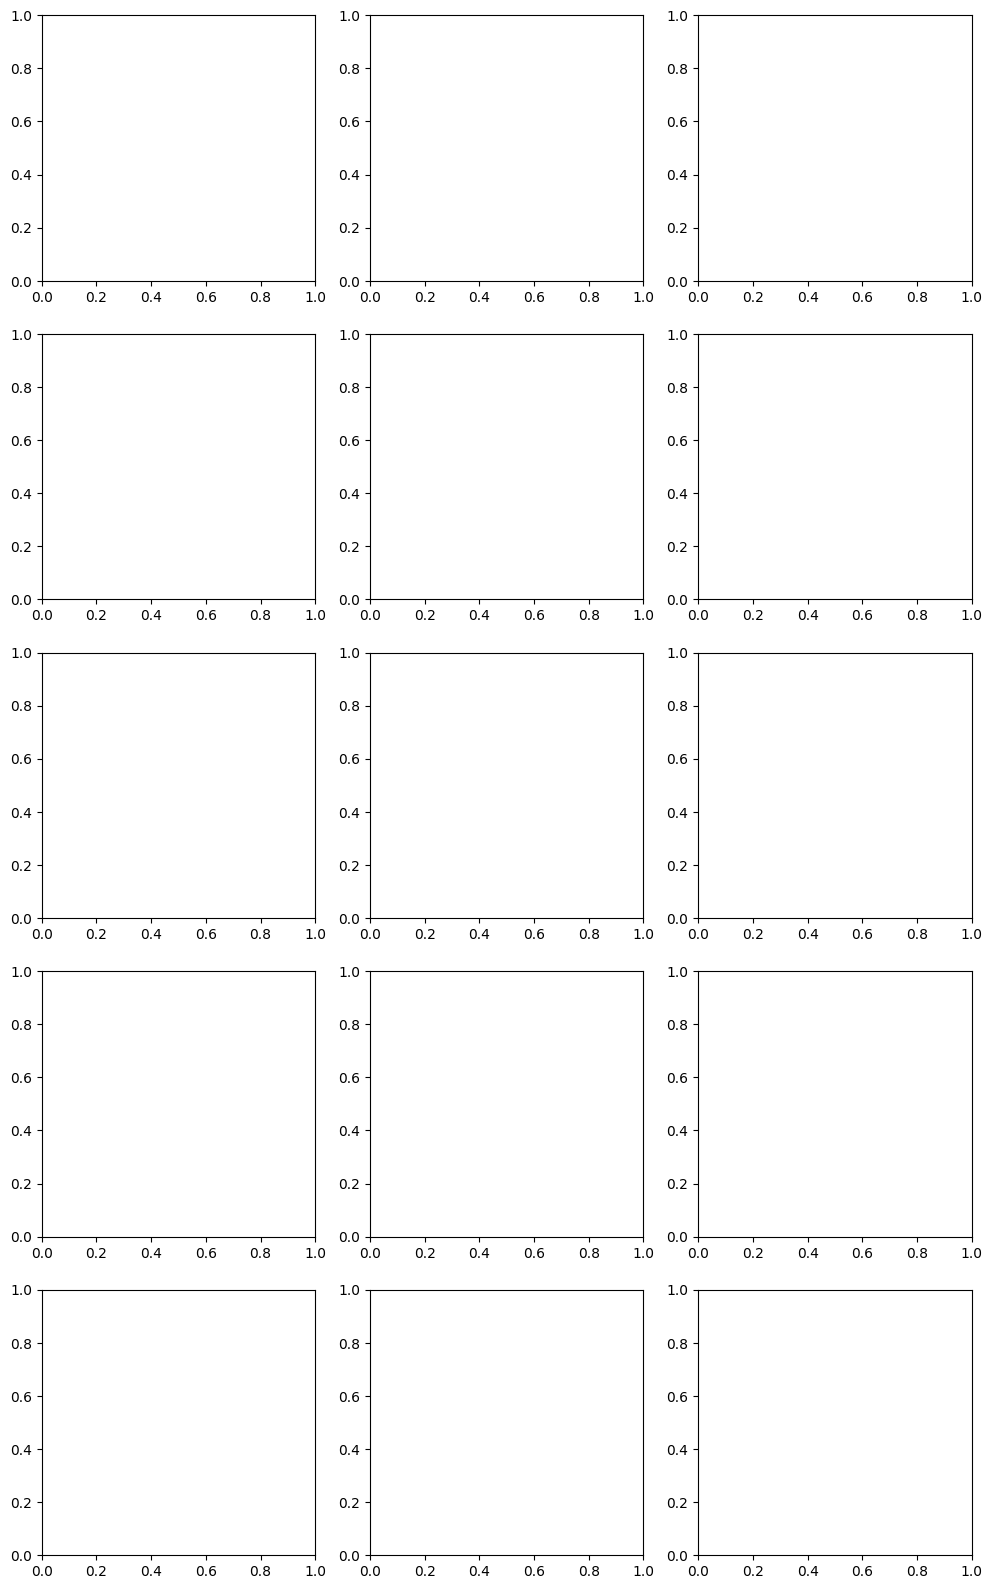

In [15]:
stime = time.time()
eigenvalues, relevant_times = petls_Rips_combined(points = chosen_points, threshold=threshold, max_dim=2)
print("Time taken for complete multiplicity operator eigenvalues using petls combined:", time.time() - stime)
_ = plot_eigenvalues(eigenvalues, relevant_times=relevant_times, plot_types=["min", "max", "n_non_zero"])